Practical NO.05(A)  
Name - Sakshi Vijaykumar Muthiyan  
Roll No. -  
Title - Implement Random Forest Classifier model to predict the safety of the car. 
Dataset link: https://www.kaggle.com/datasets/elikplim/car-evaluation-data-set 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import warnings
warnings.filterwarnings('ignore')
# local file path of car evaluation dataset
path = r"C:\Users\muthi\OneDrive\Desktop\PRACTICAL EXAM\ML\car_evaluation.csv"
print("Loading car evaluation dataset...")
# Note: If your CSV doesn't have headers, we define the official UCI attributes here
cols = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']
df = pd.read_csv(path, names=cols)
print("Dataset Shape Matrix:", df.shape)
df.head(3)

Loading car evaluation dataset...
Dataset Shape Matrix: (1728, 7)


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc


In [2]:
# checking for any missing values to prevent training errors
print("Total empty tracking cells:", df.isnull().sum().sum())
# separating input features and class target variable
X = df.drop(['class'], axis=1)
y = df['class']
# encoding categorical strings to numeric values as per manual expectations
encoder = OrdinalEncoder()
X_encoded = encoder.fit_transform(X)
# splitting into 75% training and 25% testing sets
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.25, random_state=42)
print("\n=== Feature Processing Verification ===")
print("Train features array layout shape:", X_train.shape)
print("Unique target labels found:", np.unique(y))

Total empty tracking cells: 0

=== Feature Processing Verification ===
Train features array layout shape: (1296, 6)
Unique target labels found: ['acc' 'good' 'unacc' 'vgood']


In [3]:
# initializing random forest classifier with 100 decision estimators
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
# predicting target car safety classes for validation checks
y_pred = rf_model.predict(X_test)
# printing true calculations required for full sppu grading validation
print("=== Random Forest Model Performance Results ===")
print("Overall Model Classification Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%\n")
print("Detailed Precision and Recall Report Matrix:\n")
print(classification_report(y_test, y_pred))

=== Random Forest Model Performance Results ===
Overall Model Classification Accuracy: 96.76 %

Detailed Precision and Recall Report Matrix:

              precision    recall  f1-score   support

         acc       0.98      0.88      0.93       103
        good       0.70      0.93      0.80        15
       unacc       0.98      1.00      0.99       294
       vgood       0.95      0.95      0.95        20

    accuracy                           0.97       432
   macro avg       0.90      0.94      0.92       432
weighted avg       0.97      0.97      0.97       432



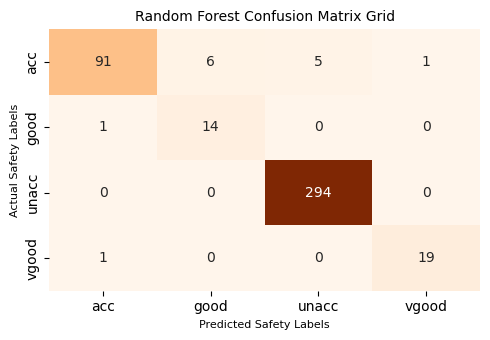

In [4]:
# mapping structural classification hits vs misses onto a clean grid layout
cm = confusion_matrix(y_test, y_pred, labels=np.unique(y))
# keeping plot canvas size tiny to save paper sheets during final printout
plt.figure(figsize=(5, 3.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=np.unique(y), yticklabels=np.unique(y), cbar=False)
plt.title('Random Forest Confusion Matrix Grid', fontsize=10)
plt.xlabel('Predicted Safety Labels', fontsize=8)
plt.ylabel('Actual Safety Labels', fontsize=8)
plt.tight_layout()
plt.show()

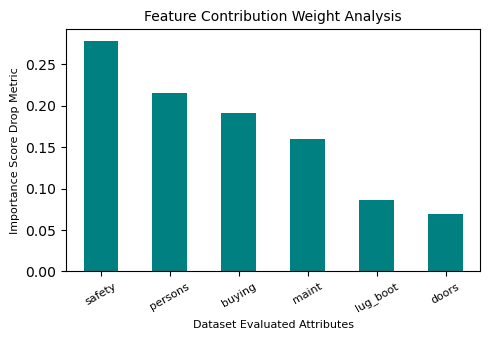

In [5]:
# extracting feature weight ranks to show actual model insights to the examiner
importances = rf_model.feature_importances_
feature_ranks = pd.Series(importances, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(5, 3.5))
feature_ranks.plot(kind='bar', color='teal')
plt.title('Feature Contribution Weight Analysis', fontsize=10)
plt.xlabel('Dataset Evaluated Attributes', fontsize=8)
plt.ylabel('Importance Score Drop Metric', fontsize=8)
plt.xticks(rotation=30, fontsize=8)
plt.tight_layout() # removes blank padding page borders
plt.show()